In [1]:
# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# --- Load data ---
data = pd.read_csv("data/heart.csv")

In [3]:
# --- Preview the data ---
data

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [4]:
# show the first 5 rows to check columns and values
data.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [5]:
# show the last 5 rows to make sure the file was read completely
data.tail()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


In [6]:
# --- Data structure ---
data.info()   # column names, non-null counts, data types, and memory usage

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [7]:
print(data.shape)   # print the dimensions of the DataFrame as (rows, columns)

(918, 12)


In [8]:
# --- Descriptive statistics (numeric columns) ---
# Note: min of RestingBP and Cholesterol is 0, which is impossible -> needs cleaning
data.describe(include=np.number)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [9]:
# --- Descriptive statistics (categorical columns) ---
# Summary of text columns: unique values, most frequent value and its frequency
data.describe(include=object)

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


In [10]:
# --- Missing values check ---
# Count NaN (empty) cells in each column; all zeros means no missing values
print(data.isna().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [11]:
# --- Duplicate rows check ---
# Count fully duplicated rows (result: 0, so no rows need to be dropped)
print(data.duplicated().sum())

0


In [12]:
# --- Target variable distribution ---
# Count patients in each class: 1 = heart disease, 0 = healthy
data["HeartDisease"].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

In [13]:
# --- Target variable proportions ---
# Share of each class (~55% heart disease / ~45% healthy) -> classes are well balanced# --- Target variable proportions ---
data["HeartDisease"].value_counts(normalize=True)

HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64

In [14]:
# --- Column summary table ---
# Build one summary table: row count, missing values and unique values for every column
pd.DataFrame({
    "count": data.shape[0],                   # total number of rows (918), repeated for every column
    "nulls": data.isnull().sum(),             # number of empty cells per column
    "nulls%": data.isnull().mean() * 100,     # percentage of empty cells per column
    "cardinality": data.nunique(),            # number of distinct values per column
})

,count,nulls,nulls%,cardinality
Age,918,0,0.0,50
Sex,918,0,0.0,2
ChestPainType,918,0,0.0,4
RestingBP,918,0,0.0,67
Cholesterol,918,0,0.0,222
FastingBS,918,0,0.0,2
RestingECG,918,0,0.0,3
MaxHR,918,0,0.0,119
ExerciseAngina,918,0,0.0,2
Oldpeak,918,0,0.0,53


In [15]:
# --- Inspect rows with Cholesterol = 0 ---
# Filter rows where cholesterol is 0 (impossible value) and count non-empty cells per column
data[data["Cholesterol"] == 0].count()

Age               172
Sex               172
ChestPainType     172
RestingBP         172
Cholesterol       172
FastingBS         172
RestingECG        172
MaxHR             172
ExerciseAngina    172
Oldpeak           172
ST_Slope          172
HeartDisease      172
dtype: int64

In [16]:
# --- Cleaning: Cholesterol = 0 ---

# Flag rows where cholesterol was recorded as 0 (1 = was 0, 0 = real value).
# 88% of these patients have heart disease, so the flag itself carries information
data["Chol_missing"] = (data["Cholesterol"] == 0).astype(int)

# 0 is physiologically impossible -> convert to NaN so it is treated as missing data
data["Cholesterol"] = data["Cholesterol"].replace(0, np.nan)

# Fill all NaN values with the overall median cholesterol
data["Cholesterol"] = data["Cholesterol"].fillna(data["Cholesterol"].median())

# Fill remaining NaN values with the median of each Sex group
# (has no effect here, because the previous line already filled every NaN)
data["Cholesterol"] = data["Cholesterol"].fillna(
    data.groupby("Sex")["Cholesterol"].transform("median"))

In [17]:
# --- Verify the cleaning of Cholesterol ---

# Summary statistics of Cholesterol after cleaning: min should now be a real value, not 0
data["Cholesterol"].describe()

# Mean cholesterol for healthy (0) vs heart disease (1) patients
data.groupby("HeartDisease")["Cholesterol"].mean()

HeartDisease
0    238.682927
1    246.854331
Name: Cholesterol, dtype: float64

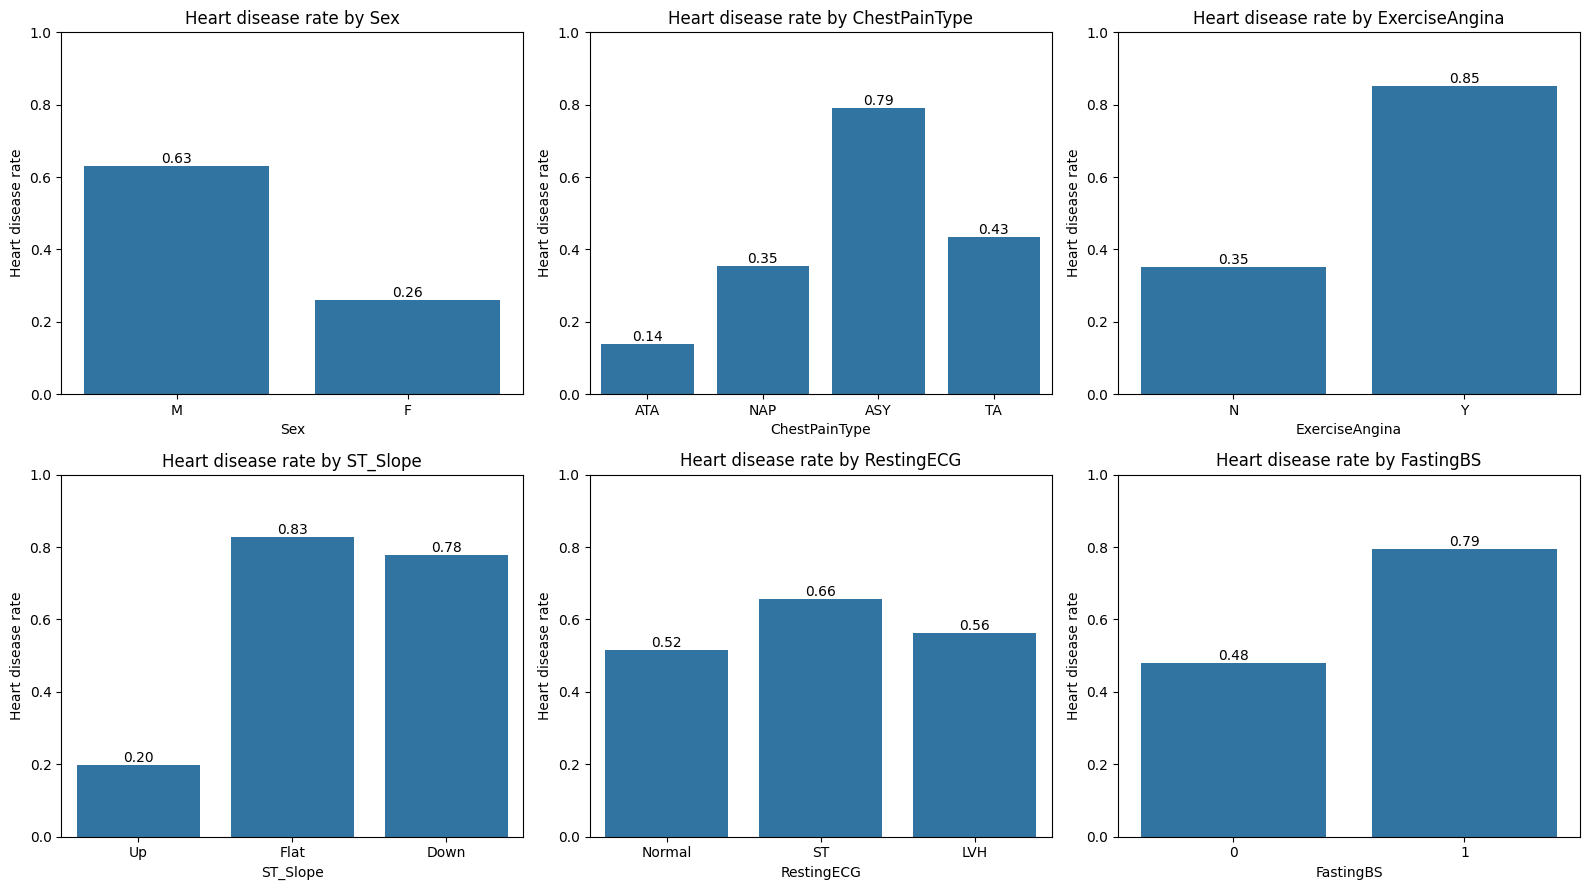

In [18]:
# --- Bar plot for categorical data ---

# Categorical columns to analyze
cat_cols = ["Sex", "ChestPainType", "ExerciseAngina", "ST_Slope", "RestingECG", "FastingBS"]

# Create a 2x3 grid of subplots (one per categorical column)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Loop over columns and axes together
for ax, col in zip(axes.flat, cat_cols):
    # Bar height = mean of HeartDisease (0/1) per category = heart disease rate
    sns.barplot(data=data, x=col, y="HeartDisease", ax=ax, errorbar=None)
    ax.set_title(f"Heart disease rate by {col}")
    ax.set_ylabel("Heart disease rate")
    ax.set_ylim(0, 1)                         # same 0-1 scale for all plots
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f")           # show the value on top of each bar

plt.tight_layout()    # prevent overlapping titles/labels
import os
os.makedirs("images", exist_ok=True)   # create the images folder if it doesn't exist
plt.savefig("images/categorical_barplots.png", dpi=150, bbox_inches="tight")  # save for README
plt.show()

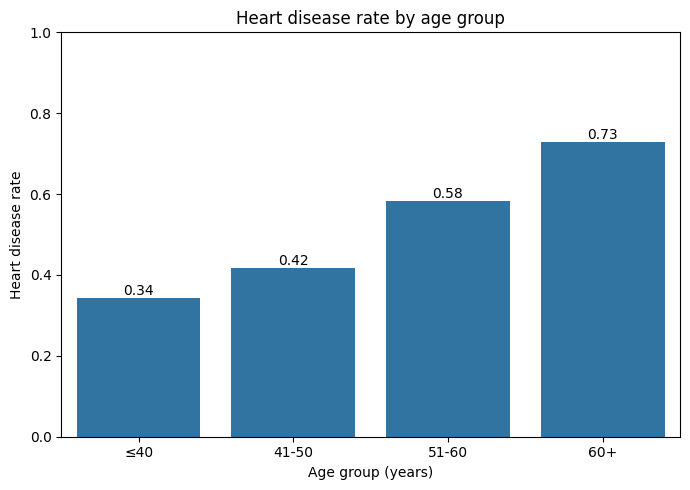

In [19]:
# --- Bar plot: heart disease rate by age group ---

# Split the continuous Age column into 4 age groups
data["AgeGroup"] = pd.cut(data["Age"],
                          bins=[0, 40, 50, 60, 100],          # group boundaries
                          labels=["≤40", "41-50", "51-60", "60+"])

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=data, x="AgeGroup", y="HeartDisease", errorbar=None)   # bar height = disease rate
ax.set_title("Heart disease rate by age group")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Heart disease rate")
ax.set_ylim(0, 1)                                  # same 0-1 scale as the other plots
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")                    # show the value on top of each bar

plt.tight_layout()
plt.savefig("images/age_barplot.png", dpi=150, bbox_inches="tight")
plt.show()

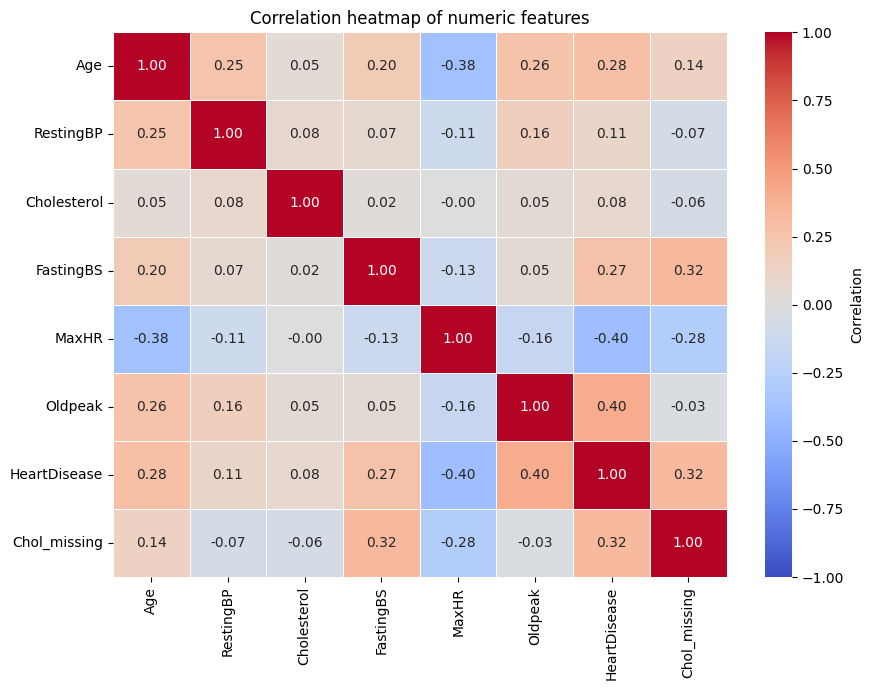

In [20]:
# --- Correlation heatmap (full matrix) ---

corr = data.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(corr,
            annot=True, fmt=".2f",      # write the correlation value in each cell
            cmap="coolwarm", center=0,  # blue = negative, red = positive
            vmin=-1, vmax=1,            # fixed correlation scale
            linewidths=0.5,
            cbar_kws={"label": "Correlation"})
plt.title("Correlation heatmap of numeric features")

plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()